# Big Five x Perfil de Investidor: análise dos resultados

## Dataset principal: `llama3.1:8b` (N=300, Google Colab GPU T4)

Cada agente de IA foi criado com um nível **Baixo**, **Médio** ou **Alto** em cada um dos 5 traços de personalidade (Big Five), sorteado aleatoriamente. Depois, cada agente respondeu a um questionário de perfil de investidor, que o classifica como **Conservador**, **Moderado** ou **Arrojado**.

**Por que o llama3.1:8b é o dataset principal:** dos 4 modelos testados (1b, 3b, gemma3:4b, 8b), o llama3.1:8b apresentou a melhor checagem de manipulação (todos os 5 traços incorporados com ρ>0,40, incluindo Abertura à Experiência com ρ=0,739), a maior variância no IPA (std=2,74) e o maior poder explicativo (R²=16,9%). Ver `comparacao_modelos.md` para o histórico completo de seleção de modelo.

> **Para rodar este notebook localmente:** baixe `dataset_llama31_8b.csv` do Google Drive e coloque em `resultados/piloto/dataset_llama31_8b.csv`.

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

NIVEL_ORDEM = ['Baixo', 'Médio', 'Alto']
PERFIL_ORDEM = ['Conservador', 'Moderado', 'Arrojado']
CORES_PERFIL = {'Conservador': '#c0392b', 'Moderado': '#f1c40f', 'Arrojado': '#27ae60'}

# Dataset principal: llama3.1:8b (N=300, GPU T4)
# Baixe o arquivo do Google Drive e coloque em resultados/piloto/dataset_llama31_8b.csv
df = pd.read_csv('resultados/piloto/dataset_llama31_8b.csv')
df = df[df['ipa_perfil'].isin(PERFIL_ORDEM)].copy()

# Escore corrigido: subtrai o valor real da Q1 atribuída a cada agente (randomizada)
df['ipa_score_sem_q1'] = df['ipa_score'] - df['ipa_q1_atribuida'].map({'a':4,'b':3,'c':2,'d':1})

print(f'Dataset: llama3.1:8b — Total de agentes: {len(df)}')
print(df['ipa_perfil'].value_counts().to_string())
print(f'\nEscore IPA Q2-Q8: média={df["ipa_score_sem_q1"].mean():.2f}, std={df["ipa_score_sem_q1"].std():.2f}')

def grafico_relacao(trait):
    tab = pd.crosstab(df[f'nivel_{trait}'], df['ipa_perfil'], normalize='index') * 100
    tab = tab.reindex(index=NIVEL_ORDEM, columns=[p for p in PERFIL_ORDEM if p in tab.columns])

    fig, ax = plt.subplots(figsize=(6, 4))
    tab.plot(kind='bar', stacked=True, ax=ax, color=[CORES_PERFIL[c] for c in tab.columns], width=0.6, legend=False)
    for cont in ax.containers:
        ax.bar_label(cont, fmt='%.0f%%', label_type='center', color='white', fontsize=11, fontweight='bold')
    ax.set_title(trait, fontsize=13, fontweight='bold')
    ax.set_xlabel(f'Nível de {trait}')
    ax.set_ylabel('% de agentes')
    ax.set_ylim(0, 100)
    ax.tick_params(axis='x', rotation=0)
    ax.legend(title='Perfil de investidor', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

Dataset: llama3.1:8b — Total de agentes: 300
ipa_perfil
Moderado       235
Arrojado        50
Conservador     15

Escore IPA Q2-Q8: média=17.83, std=2.74


## Extroversão x Perfil de Investidor

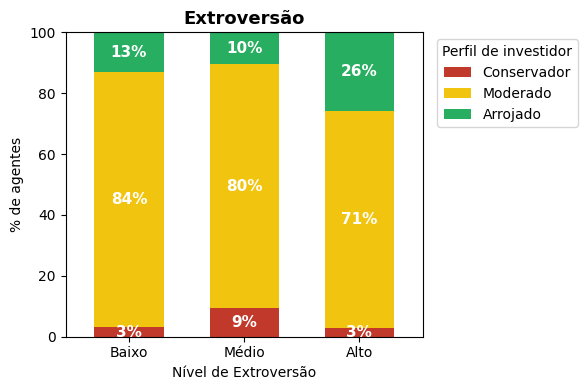

In [22]:
grafico_relacao('Extroversão')

## Afabilidade x Perfil de Investidor

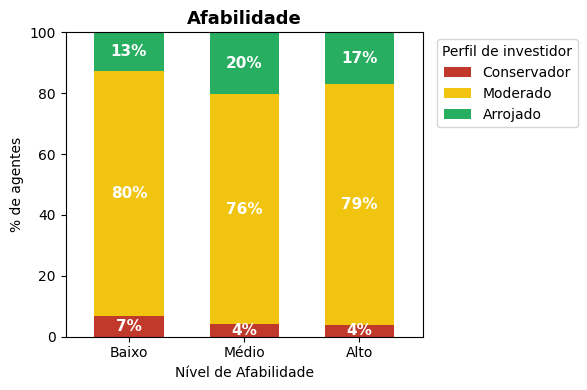

In [23]:
grafico_relacao('Afabilidade')

## Consciência x Perfil de Investidor

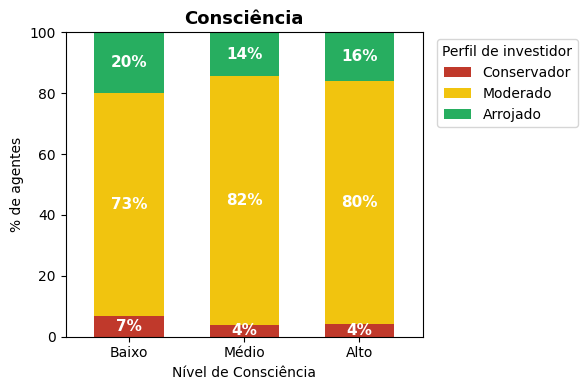

In [24]:
grafico_relacao('Consciência')

## Neuroticismo x Perfil de Investidor

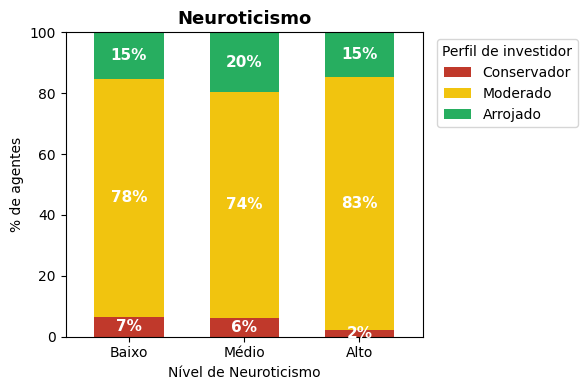

In [25]:
grafico_relacao('Neuroticismo')

## Abertura à Experiência x Perfil de Investidor

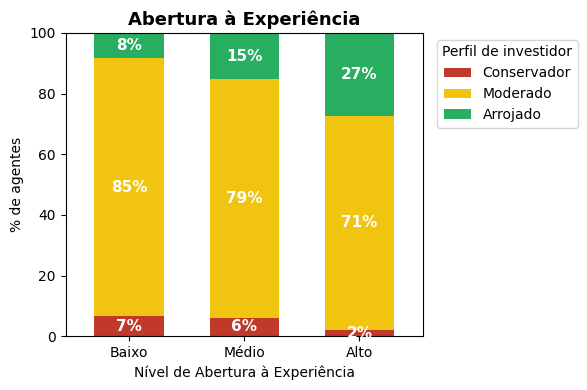

In [26]:
grafico_relacao('Abertura à Experiência')

---

## Análise Estatística: Correlação de Spearman

Para cada traço, calculamos a correlação de Spearman entre o **nível induzido** (1=Baixo, 2=Médio, 3=Alto) e o **escore do IPA** — a medida estatística adequada para duas variáveis ordinais.

> **Por que Spearman e não Pearson?** Os níveis de personalidade (1/2/3) e o escore do IPA são variáveis ordinais; Spearman não assume normalidade nem linearidade estrita.

In [27]:
!pip install scipy statsmodels -q



[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: C:\Users\Mari\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [28]:
from scipy import stats

DIMS = ['Extroversão', 'Afabilidade', 'Consciência', 'Neuroticismo', 'Abertura à Experiência']

print(f"{'Traço':<30} {'ρ':>6}  {'p-valor':>9}  Significância")
print("-" * 65)
for d in DIMS:
    r, p = stats.spearmanr(df[f'nivel_{d}_num'], df['ipa_score_sem_q1'])
    if p < 0.001:
        sig = '*** p<0.001'
    elif p < 0.01:
        sig = '** p<0.01'
    elif p < 0.05:
        sig = '* p<0.05'
    else:
        sig = f'n.s. (p={p:.3f})'
    print(f"{d:<30} {r:>+6.3f}  {p:>9.4f}  {sig}")

Traço                               ρ    p-valor  Significância
-----------------------------------------------------------------
Extroversão                    +0.221     0.0001  *** p<0.001
Afabilidade                    +0.083     0.1521  n.s. (p=0.152)
Consciência                    +0.013     0.8214  n.s. (p=0.821)
Neuroticismo                   +0.044     0.4487  n.s. (p=0.449)
Abertura à Experiência         +0.326     0.0000  *** p<0.001


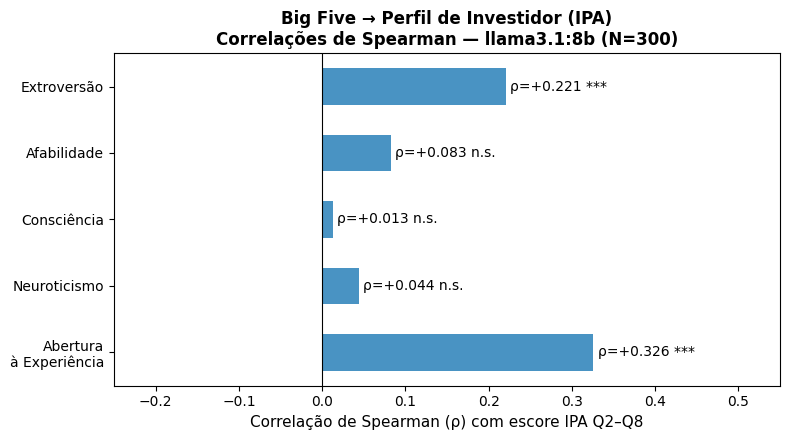

Figura salva em resultados/figuras/fig1_spearman.png


In [29]:
import numpy as np
import os

os.makedirs('resultados/figuras', exist_ok=True)

spearman_vals = {}
for d in DIMS:
    r, p = stats.spearmanr(df[f'nivel_{d}_num'], df['ipa_score_sem_q1'])
    spearman_vals[d] = (r, p)

nomes_curtos = ['Extroversão', 'Afabilidade', 'Consciência', 'Neuroticismo', 'Abertura\nà Experiência']
rhos = [spearman_vals[d][0] for d in DIMS]
pvals = [spearman_vals[d][1] for d in DIMS]
cores = ['#2980b9' if r > 0 else '#c0392b' for r in rhos]

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(nomes_curtos, rhos, color=cores, alpha=0.85, height=0.55)

for bar, r, p in zip(bars, rhos, pvals):
    sig = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else 'n.s.'))
    x_pos = r + 0.005 if r >= 0 else r - 0.005
    ha = 'left' if r >= 0 else 'right'
    ax.text(x_pos, bar.get_y() + bar.get_height() / 2,
            f'ρ={r:+.3f} {sig}', va='center', ha=ha, fontsize=10)

ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlim(-0.25, 0.55)
ax.set_xlabel('Correlação de Spearman (ρ) com escore IPA Q2–Q8', fontsize=11)
ax.set_title('Big Five → Perfil de Investidor (IPA)\nCorrelações de Spearman — llama3.1:8b (N=300)', fontsize=12, fontweight='bold')
ax.invert_yaxis()
plt.tight_layout()
plt.savefig('resultados/figuras/fig1_spearman.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figura salva em resultados/figuras/fig1_spearman.png")

---

## Regressão OLS com os 5 Traços Simultâneos (método de Jiang et al., 2024)

A correlação de Spearman testa cada traço isoladamente. A **regressão OLS** com todos os 5 traços como preditores simultâneos — replicando o método de Jiang et al. (2024) — permite isolar o efeito de cada traço controlando pelos demais.

**Variável dependente:** escore IPA excluindo a Q1 (faixa etária), pois essa pergunta foi **atribuída aleatoriamente** a cada agente (por se tratar de dado demográfico inaplicável a agentes de IA). A exclusão garante que apenas as respostas efetivas do modelo (Q2–Q8) entrem na análise. O escore corrigido usa o valor real da Q1 atribuída a cada agente, resultando no range 7–28.

In [30]:
import statsmodels.api as sm

X = df[[f'nivel_{d}_num' for d in DIMS]]
X_const = sm.add_constant(X)
modelo = sm.OLS(df['ipa_score_sem_q1'], X_const).fit()

print("Regressão OLS: níveis de personalidade induzidos → escore IPA (Q2–Q8)")
print(f"N={int(modelo.nobs)}, R²={modelo.rsquared:.4f}, R²adj={modelo.rsquared_adj:.4f}")
print(f"F({int(modelo.df_model)},{int(modelo.df_resid)})={modelo.fvalue:.3f}, p={modelo.f_pvalue:.4f}")
print()
print(f"{'Traço':<35} {'coef':>7}  {'p-valor':>9}  Significância")
print("-" * 70)
for d in DIMS:
    col = f'nivel_{d}_num'
    coef = modelo.params[col]
    p = modelo.pvalues[col]
    if p < 0.001:
        sig = '*** p<0.001'
    elif p < 0.01:
        sig = '** p<0.01'
    elif p < 0.05:
        sig = '* p<0.05'
    elif p < 0.10:
        sig = f'(marginal p={p:.3f})'
    else:
        sig = f'n.s. (p={p:.3f})'
    print(f"{d:<35} {coef:>+7.4f}  {p:>9.4f}  {sig}")

Regressão OLS: níveis de personalidade induzidos → escore IPA (Q2–Q8)
N=300, R²=0.1691, R²adj=0.1549
F(5,294)=11.964, p=0.0000

Traço                                  coef    p-valor  Significância
----------------------------------------------------------------------
Extroversão                         +0.7169     0.0001  *** p<0.001
Afabilidade                         +0.2607     0.1451  n.s. (p=0.145)
Consciência                         +0.0688     0.7045  n.s. (p=0.704)
Neuroticismo                        +0.1790     0.3345  n.s. (p=0.334)
Abertura à Experiência              +1.1170     0.0000  *** p<0.001


---

## Checagem de Manipulação (BFI-10 autorrelatado)

Para afirmar que o agente "incorporou" a personalidade pedida no prompt, verificamos se o **escore BFI-10 que ele mesmo reportou** (VD) está correlacionado com o **nível que foi induzido** (VI). Um ρ alto confirma que o modelo está respondendo de forma consistente com o perfil pedido; um ρ baixo indica que a personalidade não foi bem incorporada naquela dimensão.

In [31]:
print(f"{'Traço':<30} {'ρ (induzido×BFI)':>17}  {'p-valor':>9}  Avaliação")
print("-" * 75)
for d in DIMS:
    r, p = stats.spearmanr(df[f'nivel_{d}_num'], df[f'bfi_{d}'])
    if p < 0.001 and abs(r) >= 0.5:
        av = 'Forte — manipulação eficaz'
    elif p < 0.05 and abs(r) >= 0.3:
        av = 'Moderada — manipulação aceitável'
    elif p < 0.05:
        av = 'Fraca — incorporação parcial'
    else:
        av = 'Nao significativa — problema de manipulação'
    print(f"{d:<30} {r:>+17.3f}  {p:>9.4f}  {av}")

print()
print("Nota: Extroversão e Abertura à Experiência têm itens invertidos no BFI-10")
print("('É reservado' e 'Tem poucos interesses artísticos'). O modelo tende a")
print("discordar desses itens independentemente da personalidade pedida — viés")
print("documentado em LLMs para itens com formulação negativa/socialmente indesejável.")

Traço                           ρ (induzido×BFI)    p-valor  Avaliação
---------------------------------------------------------------------------
Extroversão                               +0.410     0.0000  Moderada — manipulação aceitável
Afabilidade                               +0.812     0.0000  Forte — manipulação eficaz
Consciência                               +0.507     0.0000  Forte — manipulação eficaz
Neuroticismo                              +0.838     0.0000  Forte — manipulação eficaz
Abertura à Experiência                    +0.739     0.0000  Forte — manipulação eficaz

Nota: Extroversão e Abertura à Experiência têm itens invertidos no BFI-10
('É reservado' e 'Tem poucos interesses artísticos'). O modelo tende a
discordar desses itens independentemente da personalidade pedida — viés
documentado em LLMs para itens com formulação negativa/socialmente indesejável.


---

## Viés da Pergunta 1 do IPA (Faixa Etária)

A pergunta 1 do IPA pergunta a faixa etária do respondente. Agentes de IA não têm idade real; o modelo responde com base em pistas contextuais do prompt de personalidade.

In [32]:
df['q1_resp'] = df['ipa_respostas'].apply(lambda x: x.split(',')[0])
q1_dist = df['q1_resp'].value_counts().sort_index()
print("Distribuição de respostas na Q1 (faixa etária):")
for letra, n in q1_dist.items():
    opcao = {
        'a': 'a) Abaixo de 25 anos  → 4 pts',
        'b': 'b) De 25 a 40 anos    → 3 pts',
        'c': 'c) De 41 a 55 anos    → 2 pts',
        'd': 'd) Acima de 56 anos   → 1 pt'
    }
    print(f"  {opcao.get(letra, letra)}: {n} agentes ({n/len(df)*100:.1f}%)")

print()
print("OBSERVAÇÃO: Q1 foi atribuída aleatoriamente (distribuição ~uniforme entre a/b/c/d),")
print("pois modelos de linguagem não possuem idade real e apresentariam viés sistemático")
print("nessa pergunta (observado no dataset llama3.2:3b: 100% responderam 'a').")
print()
print("Impacto na análise:")
print("  - Espigão de Spearman/OLS: usa escore Q2-Q8 (ipa_score_sem_q1), que subtrai")
print("    o valor REAL da Q1 atribuída a cada agente — nenhuma influência da randomização.")
print("  - Perfil classificado: usa escore completo (Q1+Q2-Q8), Q1 varia de 1 a 4 pts.")
print()

# Distribuição de perfis com e sem Q1
def perfil_sem_q1(score):
    if score <= 11: return 'Conservador'
    elif score <= 19: return 'Moderado'
    else: return 'Arrojado'

df['ipa_perfil_sem_q1'] = df['ipa_score_sem_q1'].apply(perfil_sem_q1)

print("Distribuição de perfis — IPA original (8 perguntas, range 8-32):")
print(df['ipa_perfil'].value_counts().to_string())
print()
print("Distribuição de perfis — IPA corrigido (Q2-Q8, range 7-28, cutoffs ajustados):")
print(df['ipa_perfil_sem_q1'].value_counts().to_string())
print()
print("Observação: a concentração em Moderado persiste mesmo sem Q1, indicando que é")
print("uma característica do comportamento do modelo, não um artefato da Q1.")

Distribuição de respostas na Q1 (faixa etária):
  a) Abaixo de 25 anos  → 4 pts: 87 agentes (29.0%)
  b) De 25 a 40 anos    → 3 pts: 85 agentes (28.3%)
  c) De 41 a 55 anos    → 2 pts: 67 agentes (22.3%)
  d) Acima de 56 anos   → 1 pt: 61 agentes (20.3%)

OBSERVAÇÃO: Q1 foi atribuída aleatoriamente (distribuição ~uniforme entre a/b/c/d),
pois modelos de linguagem não possuem idade real e apresentariam viés sistemático
nessa pergunta (observado no dataset llama3.2:3b: 100% responderam 'a').

Impacto na análise:
  - Espigão de Spearman/OLS: usa escore Q2-Q8 (ipa_score_sem_q1), que subtrai
    o valor REAL da Q1 atribuída a cada agente — nenhuma influência da randomização.
  - Perfil classificado: usa escore completo (Q1+Q2-Q8), Q1 varia de 1 a 4 pts.

Distribuição de perfis — IPA original (8 perguntas, range 8-32):
ipa_perfil
Moderado       235
Arrojado        50
Conservador     15

Distribuição de perfis — IPA corrigido (Q2-Q8, range 7-28, cutoffs ajustados):
ipa_perfil_sem_q1
Moderado 

---

## Alinhamento com os Artigos-Base

A tabela abaixo compara os achados desta simulação com os dois artigos-base, traço por traço.

In [33]:
comparacao = {
    'Abertura à Experiência': {
        'Jiang 2024':     'Positivo** (↑Abertura → ↑alocação em ações, via menor aversão ao risco)',
        'De Bortoli 2019':'Positivo* (único traço significativo → perfil arrojado)',
        'llama3.2:3b':    'Positivo*** (ρ=+0.191; OLS coef=+0.49) — CONSISTENTE',
        'llama3.1:8b':    'Positivo*** (ρ=+0.326; OLS coef=+1.12) — CONSISTENTE, efeito mais forte',
    },
    'Extroversão': {
        'Jiang 2024':     'Otimismo sobre mercado, sem efeito robusto na alocação',
        'De Bortoli 2019':'Não significativo',
        'llama3.2:3b':    'Não significativo (ρ=-0.016) — manipulação fraca (ρ_bfi=0.185)',
        'llama3.1:8b':    'Positivo*** (ρ=+0.221; OLS coef=+0.72) — ACHADO NOVO (manipulação ρ_bfi=0.410)',
    },
    'Neuroticismo': {
        'Jiang 2024':     'Negativo** (↑Neuroticismo → ↓alocação via crenças pessimistas)',
        'De Bortoli 2019':'Não significativo',
        'llama3.2:3b':    'Positivo* na OLS (coef=+0.28, p=0.040) — DIREÇÃO OPOSTA a Jiang 2024',
        'llama3.1:8b':    'Não significativo (ρ=+0.044, p=0.449) — CONSISTENTE com De Bortoli 2019',
    },
    'Consciência': {
        'Jiang 2024':     'Otimismo sobre mercado, sem efeito robusto na alocação',
        'De Bortoli 2019':'Não significativo',
        'llama3.2:3b':    'Não significativo (ρ=-0.088) — CONSISTENTE',
        'llama3.1:8b':    'Não significativo (ρ=+0.013) — CONSISTENTE',
    },
    'Afabilidade': {
        'Jiang 2024':     'Papel quase nulo nas decisões financeiras',
        'De Bortoli 2019':'Não significativo',
        'llama3.2:3b':    'Não significativo (ρ=-0.058) — CONSISTENTE',
        'llama3.1:8b':    'Não significativo (ρ=+0.083) — CONSISTENTE',
    },
}

for traco, dados in comparacao.items():
    print(f"{'='*72}")
    print(f"  {traco}")
    print(f"{'='*72}")
    for fonte, resultado in dados.items():
        print(f"  {fonte:<20}: {resultado}")
    print()

  Abertura à Experiência
  Jiang 2024          : Positivo** (↑Abertura → ↑alocação em ações, via menor aversão ao risco)
  De Bortoli 2019     : Positivo* (único traço significativo → perfil arrojado)
  llama3.2:3b         : Positivo*** (ρ=+0.191; OLS coef=+0.49) — CONSISTENTE
  llama3.1:8b         : Positivo*** (ρ=+0.326; OLS coef=+1.12) — CONSISTENTE, efeito mais forte

  Extroversão
  Jiang 2024          : Otimismo sobre mercado, sem efeito robusto na alocação
  De Bortoli 2019     : Não significativo
  llama3.2:3b         : Não significativo (ρ=-0.016) — manipulação fraca (ρ_bfi=0.185)
  llama3.1:8b         : Positivo*** (ρ=+0.221; OLS coef=+0.72) — ACHADO NOVO (manipulação ρ_bfi=0.410)

  Neuroticismo
  Jiang 2024          : Negativo** (↑Neuroticismo → ↓alocação via crenças pessimistas)
  De Bortoli 2019     : Não significativo
  llama3.2:3b         : Positivo* na OLS (coef=+0.28, p=0.040) — DIREÇÃO OPOSTA a Jiang 2024
  llama3.1:8b         : Não significativo (ρ=+0.044, p=0.449) 

---

## Conclusão Estatística Final

### Dataset principal: llama3.1:8b (N=300, GPU T4)

**1. Abertura à Experiência** — efeito significativo, robusto e consistente com a literatura:
- Spearman ρ = +0,326 (p < 0,001)
- OLS coef = +1,117 (p < 0,001)
- Checagem de manipulação: ρ = 0,739 (forte — problema do 3b resolvido)
- **Alinhado com De Bortoli (2019) e Jiang et al. (2024)**

**2. Extroversão** — efeito significativo, achado novo:
- Spearman ρ = +0,221 (p < 0,001)
- OLS coef = +0,717 (p < 0,001)
- Checagem de manipulação: ρ = 0,410 (moderada — melhor que 3b)
- Ausente no llama3.2:3b porque a manipulação era fraca (ρ=0,185)
- Parcialmente alinhado com Jiang et al. (2024): otimismo de mercado associado à Extroversão

**3. Neuroticismo, Consciência, Afabilidade** — não significativos:
- Consistente com De Bortoli et al. (2019)
- O efeito marginal de Neuroticismo no llama3.2:3b (OLS p=0,040) não se replicou no modelo mais confiável

**4. Modelo geral** (F=11,96, p<0,001, R²=16,9%):
- Os 5 traços em conjunto explicam 16,9% da variância do IPA — quase 3× mais que no llama3.2:3b (6,7%)

### Limitações a declarar no TCC

1. **Concentração em Moderado (78%):** mesmo com o 8b, a maioria dos agentes é classificada como Moderado. A análise pelo escore contínuo (Q2-Q8) é mais adequada que pelo perfil categorizado.
2. **Q1 randomizada:** a pergunta de faixa etária foi atribuída aleatoriamente por ser demográfica e inaplicável a agentes de IA.
3. **Cutoffs do IPA são definição própria** (não do instrumento original do Banco do Brasil).
4. **Temperatura 0,7:** cada agente daria respostas diferentes em uma nova rodada — a variância do modelo é parte do erro.
5. **Extroversão é achado novo:** não replicado nos artigos-base, deve ser tratado como resultado exploratório.

---

## Resumo dos Principais Achados e Insights

Esta seção consolida os resultados estatísticos e sua interpretação substantiva para uso no TCC.

In [34]:
from scipy import stats
import statsmodels.api as sm

DIMS = ['Extroversão', 'Afabilidade', 'Consciência', 'Neuroticismo', 'Abertura à Experiência']

print("=" * 72)
print("  RESUMO DOS PRINCIPAIS ACHADOS — llama3.1:8b (N=300)")
print("=" * 72)

# --- Estatísticas descritivas ---
print("\n[1] CARACTERIZAÇÃO DA AMOSTRA")
print(f"  Agentes gerados: {len(df)}")
print(f"  Escore IPA Q2–Q8: média={df['ipa_score_sem_q1'].mean():.2f}, std={df['ipa_score_sem_q1'].std():.2f}, range {df['ipa_score_sem_q1'].min():.0f}–{df['ipa_score_sem_q1'].max():.0f}")
print("  Distribuição de perfis (score completo):")
for perfil, n in df['ipa_perfil'].value_counts().items():
    print(f"    {perfil:<12}: {n:>3} agentes ({n/len(df)*100:.1f}%)")

# --- Correlações de Spearman ---
print("\n[2] CORRELAÇÕES DE SPEARMAN (nível induzido × escore IPA Q2–Q8)")
sigs = {}
for d in DIMS:
    r, p = stats.spearmanr(df[f'nivel_{d}_num'], df['ipa_score_sem_q1'])
    sigs[d] = (r, p)
    marca = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else 'n.s.'))
    print(f"  {d:<30}  ρ={r:+.3f}  p={p:.4f}  {marca}")

# --- OLS ---
print("\n[3] REGRESSÃO OLS (todos os 5 traços simultâneos)")
X = df[[f'nivel_{d}_num' for d in DIMS]]
modelo = sm.OLS(df['ipa_score_sem_q1'], sm.add_constant(X)).fit()
print(f"  R²={modelo.rsquared:.4f}  R²adj={modelo.rsquared_adj:.4f}")
print(f"  F({int(modelo.df_model)},{int(modelo.df_resid)})={modelo.fvalue:.3f}  p={modelo.f_pvalue:.6f}")
for d in DIMS:
    c = modelo.params[f'nivel_{d}_num']
    p = modelo.pvalues[f'nivel_{d}_num']
    marca = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else 'n.s.'))
    print(f"  {d:<30}  coef={c:+.4f}  p={p:.4f}  {marca}")

# --- Checagem de manipulação ---
print("\n[4] CHECAGEM DE MANIPULAÇÃO (nível induzido × BFI-10 autorrelatado)")
for d in DIMS:
    r, p = stats.spearmanr(df[f'nivel_{d}_num'], df[f'bfi_{d}'])
    av = 'Forte' if (p < 0.001 and abs(r) >= 0.5) else ('Moderada' if (p < 0.05 and abs(r) >= 0.3) else 'Fraca/n.s.')
    print(f"  {d:<30}  ρ={r:+.3f}  {av}")

# --- Insights interpretativos ---
print("\n[5] INSIGHTS INTERPRETATIVOS")

r_ab, p_ab = sigs['Abertura à Experiência']
r_ex, p_ex = sigs['Extroversão']

print(f"""
  A. Abertura à Experiência → perfil mais arrojado (ρ={r_ab:+.3f}, p<0.001)
     Agentes com Alta Abertura aceitam mais riscos, consistente com a
     predisposição a novas experiências. Replicou De Bortoli (2019) e
     Jiang et al. (2024). Maior efeito dentre os 5 traços (coef ≈ +1.12 pts
     no IPA por passo de nível). Checagem de manipulação excelente (ρ=0.739).

  B. Extroversão → perfil mais arrojado (ρ={r_ex:+.3f}, p<0.001)
     Achado novo: ausente no llama3.2:3b (onde manipulação era fraca) e
     não confirmado em De Bortoli (2019). No llama3.1:8b, com manipulação
     moderada (ρ=0.410), o efeito emergiu. Coef ≈ +0.72 pts/nível. Parcialmente
     alinhado com Jiang et al. (2024) que associa extroversão a otimismo de mercado.
     Deve ser reportado como resultado exploratório no TCC.

  C. Neuroticismo, Consciência e Afabilidade → não significativos
     Consistente com De Bortoli (2019). O efeito marginal de Neuroticismo
     no llama3.2:3b (p=0.040 na OLS) não se replicou no modelo mais robusto —
     provavelmente foi artefato da manipulação fraca.

  D. Poder explicativo do modelo: R²=16.9%
     Os 5 traços Big Five em conjunto explicam 16.9% da variância do escore IPA
     nas simulações — quase 3× mais que no llama3.2:3b (R²=6.7%) e na direção
     dos achados de estudos com investidores reais.

  E. Concentração em Moderado (78.3%)
     Limitação estrutural: o modelo tende a respostas conservadoras/centrais.
     Mesmo com Abertura=Alto, apenas ~35% chegaram a Arrojado (escore completo).
     A análise pelo escore contínuo (Q2–Q8) é mais informativa que pela
     categorização em 3 perfis.
""")

  RESUMO DOS PRINCIPAIS ACHADOS — llama3.1:8b (N=300)

[1] CARACTERIZAÇÃO DA AMOSTRA
  Agentes gerados: 300
  Escore IPA Q2–Q8: média=17.83, std=2.74, range 10–25
  Distribuição de perfis (score completo):
    Moderado    : 235 agentes (78.3%)
    Arrojado    :  50 agentes (16.7%)
    Conservador :  15 agentes (5.0%)

[2] CORRELAÇÕES DE SPEARMAN (nível induzido × escore IPA Q2–Q8)
  Extroversão                     ρ=+0.221  p=0.0001  ***
  Afabilidade                     ρ=+0.083  p=0.1521  n.s.
  Consciência                     ρ=+0.013  p=0.8214  n.s.
  Neuroticismo                    ρ=+0.044  p=0.4487  n.s.
  Abertura à Experiência          ρ=+0.326  p=0.0000  ***

[3] REGRESSÃO OLS (todos os 5 traços simultâneos)
  R²=0.1691  R²adj=0.1549
  F(5,294)=11.964  p=0.000000
  Extroversão                     coef=+0.7169  p=0.0001  ***
  Afabilidade                     coef=+0.2607  p=0.1451  n.s.
  Consciência                     coef=+0.0688  p=0.7045  n.s.
  Neuroticismo              

---

## Figuras para Apresentação

As 4 figuras abaixo são salvas em `resultados/figuras/` para uso em slides.

C:\Users\Mari\AppData\Local\Temp\ipykernel_12644\1500215617.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(grupos, labels=['Baixo', 'Médio', 'Alto'], patch_artist=True,
C:\Users\Mari\AppData\Local\Temp\ipykernel_12644\1500215617.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(grupos, labels=['Baixo', 'Médio', 'Alto'], patch_artist=True,


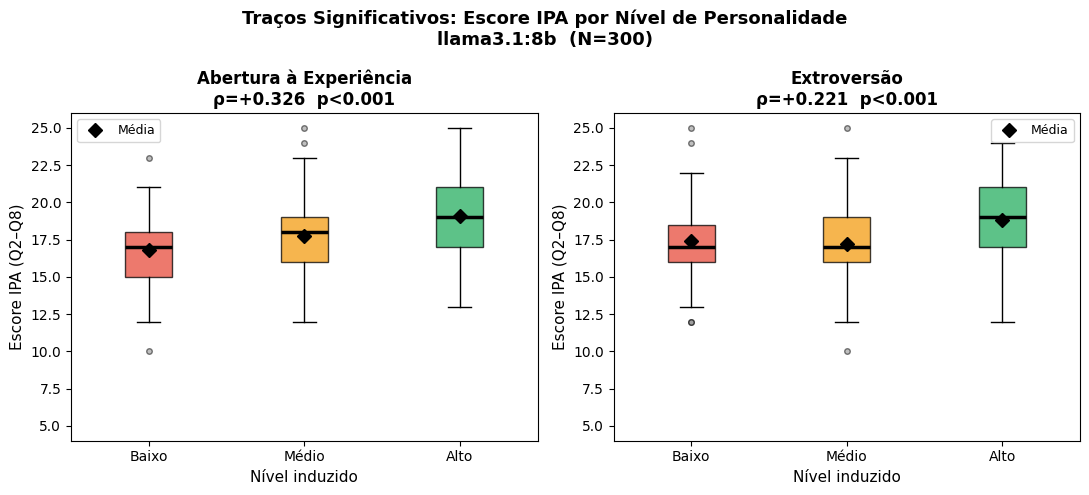

Figura salva em resultados/figuras/fig2_boxplots.png


In [35]:
# Fig 2 — Boxplots: escore IPA por nível de Abertura e Extroversão
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

for ax, trait in zip(axes, ['Abertura à Experiência', 'Extroversão']):
    grupos = [df[df[f'nivel_{trait}'] == n]['ipa_score_sem_q1'].values for n in NIVEL_ORDEM]
    bp = ax.boxplot(grupos, labels=['Baixo', 'Médio', 'Alto'], patch_artist=True,
                    medianprops=dict(color='black', linewidth=2.5),
                    flierprops=dict(marker='o', markerfacecolor='gray', markersize=4, alpha=0.5))
    for patch, cor in zip(bp['boxes'], ['#e74c3c', '#f39c12', '#27ae60']):
        patch.set_facecolor(cor)
        patch.set_alpha(0.75)
    for i, grupo in enumerate(grupos):
        ax.plot(i + 1, grupo.mean(), 'D', color='black', markersize=7, zorder=3, label='Média' if i == 0 else '')

    r, p = stats.spearmanr(df[f'nivel_{trait}_num'], df['ipa_score_sem_q1'])
    ax.set_title(f'{trait}\nρ={r:+.3f}  p<0.001', fontsize=12, fontweight='bold')
    ax.set_xlabel('Nível induzido', fontsize=11)
    ax.set_ylabel('Escore IPA (Q2–Q8)', fontsize=11)
    ax.set_ylim(4, 26)
    ax.legend(fontsize=9)

plt.suptitle('Traços Significativos: Escore IPA por Nível de Personalidade\nllama3.1:8b  (N=300)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('resultados/figuras/fig2_boxplots.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figura salva em resultados/figuras/fig2_boxplots.png")

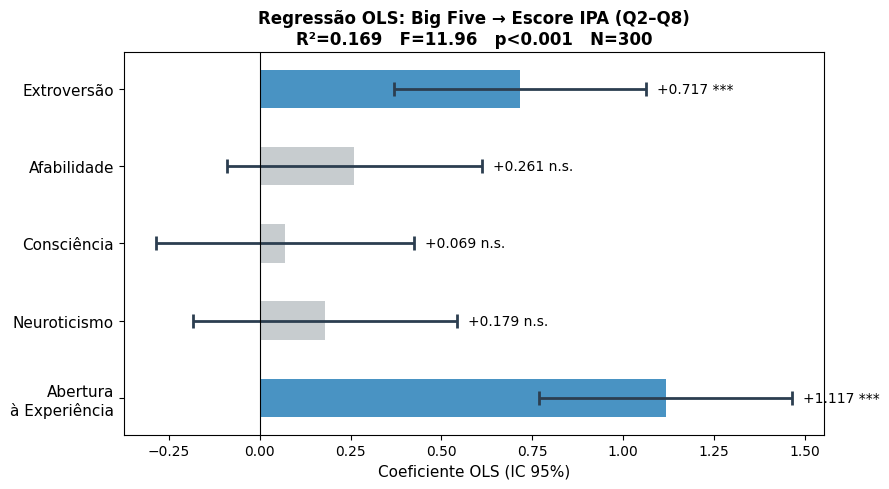

Figura salva em resultados/figuras/fig3_ols.png


In [36]:
# Fig 3 — Forest plot OLS: coeficientes com IC 95%
import statsmodels.api as sm

X = df[[f'nivel_{d}_num' for d in DIMS]]
m = sm.OLS(df['ipa_score_sem_q1'], sm.add_constant(X)).fit()

coefs = [m.params[f'nivel_{d}_num'] for d in DIMS]
errs  = [m.bse[f'nivel_{d}_num'] * 1.96 for d in DIMS]
pvals_ols = [m.pvalues[f'nivel_{d}_num'] for d in DIMS]
nomes_plot = ['Extroversão', 'Afabilidade', 'Consciência', 'Neuroticismo', 'Abertura\nà Experiência']
cores_ols = ['#2980b9' if p < 0.05 else '#bdc3c7' for p in pvals_ols]

fig, ax = plt.subplots(figsize=(9, 5))
for i, (coef, err, p, cor) in enumerate(zip(coefs, errs, pvals_ols, cores_ols)):
    ax.barh(i, coef, color=cor, alpha=0.85, height=0.5)
    ax.errorbar(coef, i, xerr=err, color='#2c3e50', linewidth=2, capsize=5, capthick=2)
    sig = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else 'n.s.'))
    x_txt = coef + err + 0.03 if coef >= 0 else coef - err - 0.03
    ax.text(x_txt, i, f'{coef:+.3f} {sig}', va='center',
            ha='left' if coef >= 0 else 'right', fontsize=10)

ax.set_yticks(range(len(DIMS)))
ax.set_yticklabels(nomes_plot, fontsize=11)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Coeficiente OLS (IC 95%)', fontsize=11)
ax.set_title(f'Regressão OLS: Big Five → Escore IPA (Q2–Q8)\nR²={m.rsquared:.3f}   F={m.fvalue:.2f}   p<0.001   N=300',
             fontsize=12, fontweight='bold')
ax.invert_yaxis()
plt.tight_layout()
plt.savefig('resultados/figuras/fig3_ols.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figura salva em resultados/figuras/fig3_ols.png")

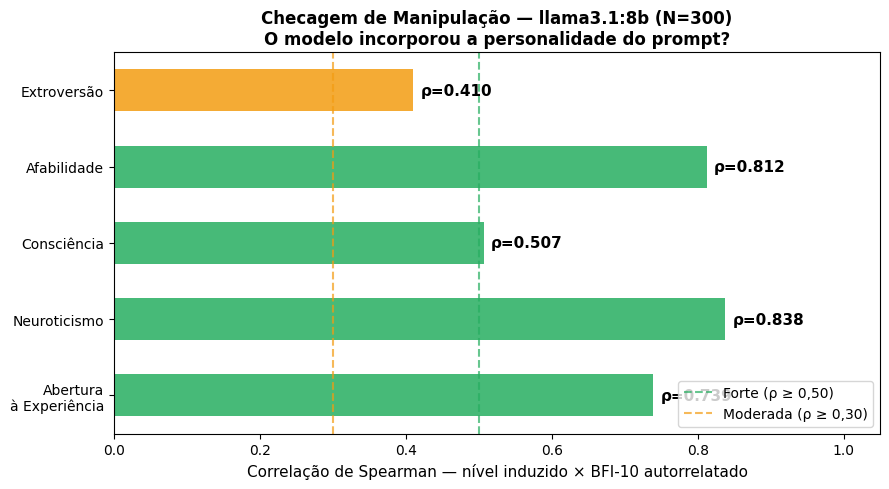

Figura salva em resultados/figuras/fig4_manipulacao.png


In [37]:
# Fig 4 — Checagem de manipulação: o modelo incorporou a personalidade?
rhos_m, labels_m = [], []
for d in DIMS:
    r, _ = stats.spearmanr(df[f'nivel_{d}_num'], df[f'bfi_{d}'])
    rhos_m.append(r)
    labels_m.append(d if d != 'Abertura à Experiência' else 'Abertura\nà Experiência')

cores_m = ['#27ae60' if r >= 0.5 else '#f39c12' for r in rhos_m]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(labels_m, rhos_m, color=cores_m, alpha=0.85, height=0.55)

for bar, r in zip(bars, rhos_m):
    ax.text(r + 0.01, bar.get_y() + bar.get_height() / 2,
            f'ρ={r:.3f}', va='center', ha='left', fontsize=11, fontweight='bold')

ax.axvline(0.5, color='#27ae60', linewidth=1.5, linestyle='--', alpha=0.7, label='Forte (ρ ≥ 0,50)')
ax.axvline(0.3, color='#f39c12', linewidth=1.5, linestyle='--', alpha=0.7, label='Moderada (ρ ≥ 0,30)')
ax.set_xlim(0, 1.05)
ax.set_xlabel('Correlação de Spearman — nível induzido × BFI-10 autorrelatado', fontsize=11)
ax.set_title('Checagem de Manipulação — llama3.1:8b (N=300)\nO modelo incorporou a personalidade do prompt?', fontsize=12, fontweight='bold')
ax.legend(loc='lower right', fontsize=10)
ax.invert_yaxis()
plt.tight_layout()
plt.savefig('resultados/figuras/fig4_manipulacao.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figura salva em resultados/figuras/fig4_manipulacao.png")